 PREVIEW DATA ASLI (30 RESPONDEN) 
         Q4  Q9  Q12
0  2.872701   3  2.0
1  5.753572   2  4.0
2  4.659970   1  4.0
3  3.993292   5  3.0
4  1.780093   5  1.0


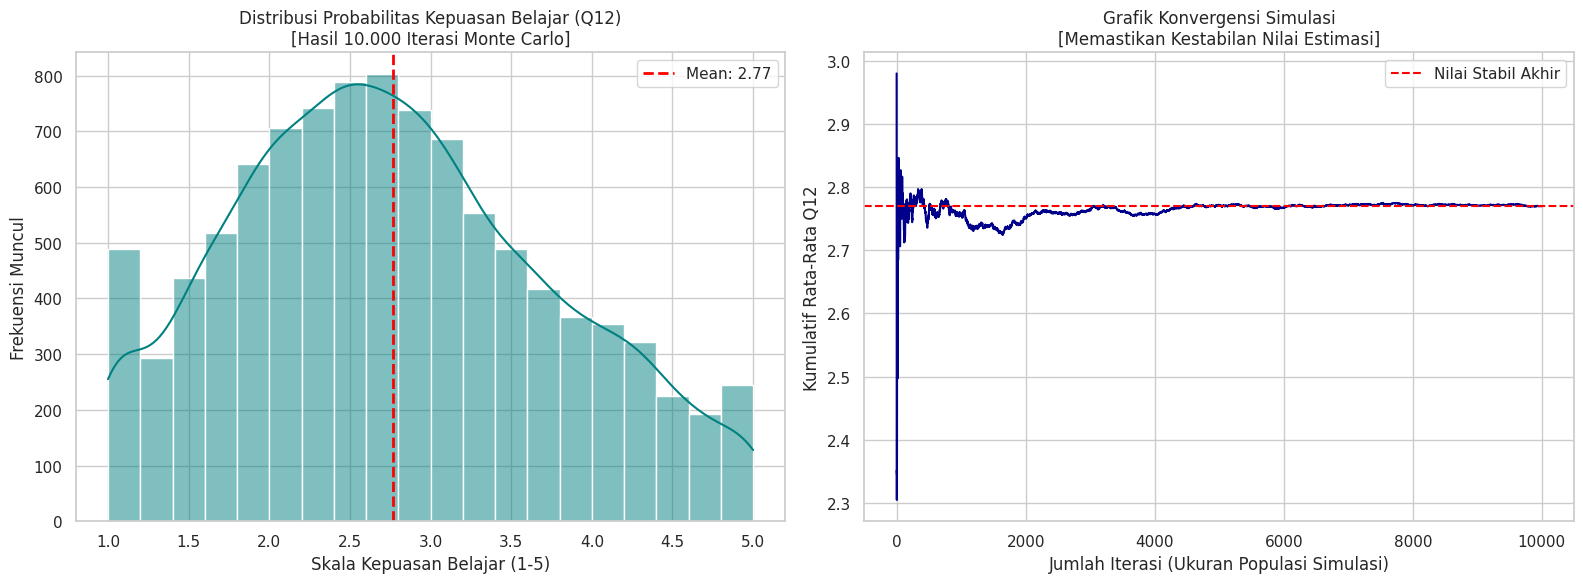


--- STATISTIK DESKRIPTIF HASIL SIMULASI MONTE CARLO ---
Rata-rata Skor Kepuasan Belajar Baru : 2.77
Standar Deviasi Kepuasan Belajar     : 0.98
Probabilitas Kepuasan Belajar >= 4.0 : 13.37%
Probabilitas Kepuasan Belajar <= 2.0 : 23.77%


In [5]:
# SIMULASI MONTE CARLO: KEBIASAAN BELAJAR MAHASISWA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [12, 5]

# (Agar kode ini bisa langsung di-run sebagai contoh) ---
np.random.seed(42)
mock_jam_belajar = np.random.uniform(1, 6, 30) # Q4: Jam Belajar (1-6 jam)
mock_distraksi = np.random.choice([1, 2, 3, 4, 5], size=30, p=[0.1, 0.2, 0.4, 0.2, 0.1]) # Q9: Skala 1-5
# Kepuasan Belajar (Q12) dibuat memiliki hubungan logis: + Jam Belajar, - Distraksi
mock_kepuasan = 3.0 + (0.4 * mock_jam_belajar) - (0.5 * mock_distraksi) + np.random.normal(0, 0.4, 30)
mock_kepuasan = np.clip(np.round(mock_kepuasan), 1, 5) # Batasi skala 1-5

df_original = pd.DataFrame({
    'Q4': mock_jam_belajar,
    'Q9': mock_distraksi,
    'Q12': mock_kepuasan
})

print(" PREVIEW DATA ASLI (30 RESPONDEN) ")
print(df_original.head())

X = df_original[['Q4', 'Q9']]
y = df_original['Q12']

model = LinearRegression()
model.fit(X, y)
prediksi_asli = model.predict(X)
residual = y - prediksi_asli
std_residual = np.std(residual)

n_iterasi = 10000


indeks_simulasi = np.random.choice(df_original.index, size=n_iterasi, replace=True)
df_simulasi = df_original.loc[indeks_simulasi, ['Q4', 'Q9']].reset_index(drop=True)

# Menghitung nilai dasar Q12 hasil prediksi model regresi
q12_prediksi_dasar = model.predict(df_simulasi)

# Menginjeksikan ketidakpastian (Stochastic Noise) menggunakan distribusi normal dari residual asli
noise_stokastik = np.random.normal(0, std_residual, n_iterasi)
q12_simulasi_kontinu = q12_prediksi_dasar + noise_stokastik

# Memastikan hasil simulasi tetap berada dalam batas skala psikometrik 1 sampai 5
q12_simulasi_final = np.clip(q12_simulasi_kontinu, 1, 5)
df_simulasi['Q12_Simulasi'] = q12_simulasi_final

# Hitung nilai rata-rata bergerak (running mean) untuk melihat konvergensi simulasi
running_mean = np.cumsum(q12_simulasi_final) / np.arange(1, n_iterasi + 1)


# VISUALISASI HASIL SIMULASI

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Grafik 1: Histogram Distribusi Kepuasan Belajar Hasil Simulasi
sns.histplot(df_simulasi['Q12_Simulasi'], bins=20, kde=True, color='teal', ax=axes[0])
axes[0].axvline(df_simulasi['Q12_Simulasi'].mean(), color='red', linestyle='--', linewidth=2,
                label=f"Mean: {df_simulasi['Q12_Simulasi'].mean():.2f}")
axes[0].set_title("Distribusi Probabilitas Kepuasan Belajar (Q12)\n[Hasil 10.000 Iterasi Monte Carlo]", fontsize=12)
axes[0].set_xlabel("Skala Kepuasan Belajar (1-5)")
axes[0].set_ylabel("Frekuensi Muncul")
axes[0].legend()

# Grafik 2: Garis Konvergensi Simulasi Monte Carlo
axes[1].plot(running_mean, color='darkblue', linewidth=1.5)
axes[1].axhline(df_simulasi['Q12_Simulasi'].mean(), color='red', linestyle='--', label="Nilai Stabil Akhir")
axes[1].set_title("Grafik Konvergensi Simulasi\n[Memastikan Kestabilan Nilai Estimasi]", fontsize=12)
axes[1].set_xlabel("Jumlah Iterasi (Ukuran Populasi Simulasi)")
axes[1].set_ylabel("Kumulatif Rata-Rata Q12")
axes[1].legend()

plt.tight_layout()
plt.show()

# Menampilkan statistik deskriptif hasil simulasi
print("\n--- STATISTIK DESKRIPTIF HASIL SIMULASI MONTE CARLO ---")
print(f"Rata-rata Skor Kepuasan Belajar Baru : {df_simulasi['Q12_Simulasi'].mean():.2f}")
print(f"Standar Deviasi Kepuasan Belajar     : {df_simulasi['Q12_Simulasi'].std():.2f}")
print(f"Probabilitas Kepuasan Belajar >= 4.0 : {(df_simulasi['Q12_Simulasi'] >= 4.0).mean() * 100:.2f}%")
print(f"Probabilitas Kepuasan Belajar <= 2.0 : {(df_simulasi['Q12_Simulasi'] <= 2.0).mean() * 100:.2f}%")